In [2]:
%pip install pandas matplotlib seaborn

^C
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv(r"C:\Users\pc\Desktop\project hcl\monthly_expenses_250.csv")
df.head()

,Name,Age,Job,Monthly Expense
0,Advaith Verma,28,Graphic Designer,"?28,400"
1,Pranav Rathore,25,UX Designer,"?55,600"
2,Arjun Verma,33,Product Manager,"?75,500"
3,Preeti Verma,29,UX Designer,"?63,600"
4,Aditi Pandey,56,Doctor,"?1,27,500"


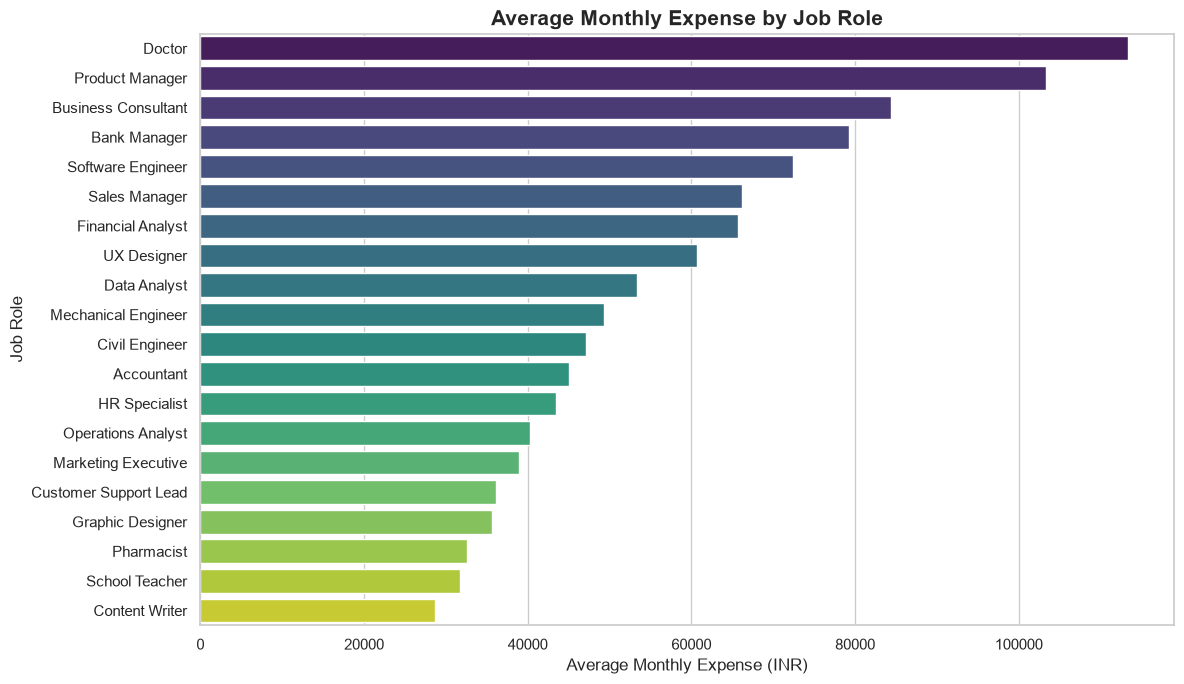

In [ ]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load your dataset
df = pd.read_csv(r"C:\Users\pc\Desktop\project hcl\monthly_expenses_250.csv")
df.columns = df.columns.str.strip()

# 2. Strip '₹', commas, or spaces and convert 'Monthly Expense' into pure numbers
df['Monthly Expense'] = (df['Monthly Expense']
    .astype(str)
    .str.replace(r'[^\d.]', '', regex=True)
)
df['Monthly Expense'] = pd.to_numeric(df['Monthly Expense'], errors='coerce')

# 3. Create the horizontal bar chart
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 7), facecolor='white')

avg_expense = df.groupby('Job')['Monthly Expense'].mean().sort_values(ascending=False)

sns.barplot(
    x=avg_expense.values, 
    y=avg_expense.index, 
    hue=avg_expense.index, 
    palette='viridis', 
    legend=False,
    ax=ax
)

ax.set_title('Average Monthly Expense by Job Role', fontsize=15, fontweight='bold')
ax.set_xlabel('Average Monthly Expense (INR)', fontsize=12)
ax.set_ylabel('Job Role', fontsize=12)

plt.tight_layout()
plt.show()

Missing values per column:
 Name               0
Age                0
Job                0
Monthly Expense    0
dtype: int64


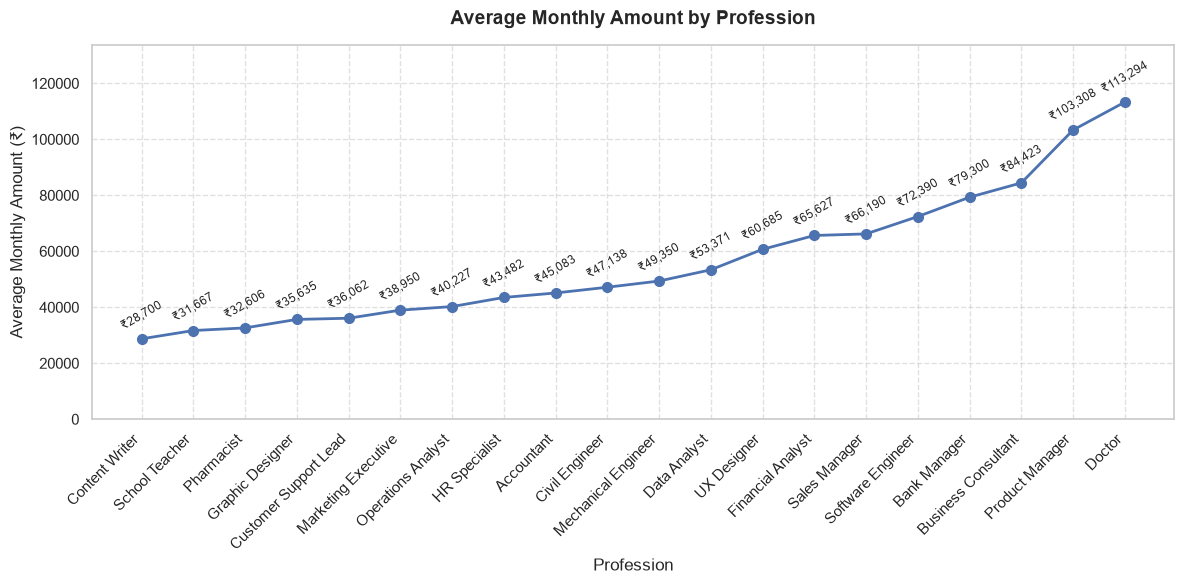

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Replace 'your_file.csv' with your actual CSV filename
df = pd.read_csv(r"C:\Users\pc\Desktop\project hcl\monthly_expenses_250.csv")

# 2. Check and handle null values
print("Missing values per column:\n", df.isnull().sum())
df = df.dropna(subset=['Job', 'Monthly Expense'])

# 3. Clean the 'Monthly Expense' column
df['Amount'] = (
    df['Monthly Expense']
    .astype(str)
    .str.replace('?', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

# 4. Group by 'Job' and calculate average monthly amount
profession_avg = df.groupby('Job')['Amount'].mean().sort_values(ascending=True)

# 5. Plot the Line Graph
plt.figure(figsize=(12, 6))
plt.plot(
    profession_avg.index, 
    profession_avg.values, 
    marker='o', 
    linestyle='-', 
    linewidth=2, 
    markersize=7, 
    color='#4C72B0'
)

for i, val in enumerate(profession_avg.values):
    plt.text(i, val + 2500, f'₹{val:,.0f}', ha='center', va='bottom', fontsize=8.5, rotation=30)

plt.title('Average Monthly Amount by Profession', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Profession', fontsize=12)
plt.ylabel('Average Monthly Amount (₹)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.ylim(0, profession_avg.max() * 1.18)
plt.tight_layout()
plt.show()


In [6]:
import os
import pandas as pd


def load_and_clean_data(filepath: str) -> pd.DataFrame:
    """Loads the CSV and converts Monthly Expense into clean integers."""
    df = pd.read_csv(filepath)
    df["Expense_Clean"] = (
        df["Monthly Expense"]
        .astype(str)
        .str.replace(r"[?,]", "", regex=True)
        .astype(int)
    )
    # Create 10-year age brackets
    bins = [19, 29, 39, 49, 59]
    labels = ["20-29", "30-39", "40-49", "50-59"]
    df["Age_Group"] = pd.cut(df["Age"], bins=bins, labels=labels)
    return df


def summarize_database(df: pd.DataFrame) -> None:
    """Prints dataset overview, age breakdown, profession breakdown, and top highlights."""
    print("=" * 65)
    print("1. DATASET OVERVIEW")
    print("=" * 65)
    print(f"Total Records : {len(df)}")
    print(f"Total Columns : {df.shape[1]}")
    print(f"Unique Jobs   : {df['Job'].nunique()}")
    print(f"Age Range     : {df['Age'].min()} to {df['Age'].max()} years")
    print(f"Missing Values: {df.isnull().sum().sum()}\n")

    print("=" * 65)
    print("2. OVERALL NUMERICAL SUMMARY")
    print("=" * 65)
    print(df[["Age", "Expense_Clean"]].describe().round(1), "\n")

    print("=" * 65)
    print("3. SUMMARY BY AGE GROUP (RANKED BY AVG EXPENSE)")
    print("=" * 65)
    age_group_summary = (
        df.groupby("Age_Group", observed=False)
        .agg(
            Headcount=("Name", "count"),
            Avg_Expense=("Expense_Clean", "mean"),
            Min_Expense=("Expense_Clean", "min"),
            Max_Expense=("Expense_Clean", "max"),
        )
        .sort_values(by="Avg_Expense", ascending=False)
        .round(1)
    )
    print(age_group_summary.to_string(), "\n")

    print("=" * 65)
    print("4. TOP 5 INDIVIDUAL AGES BY AVERAGE EXPENSE")
    print("=" * 65)
    exact_age_summary = (
        df.groupby("Age")
        .agg(
            Headcount=("Name", "count"),
            Avg_Expense=("Expense_Clean", "mean"),
            Max_Expense=("Expense_Clean", "max"),
        )
        .sort_values(by="Avg_Expense", ascending=False)
        .round(1)
    )
    print(exact_age_summary.head(5).to_string(), "\n")

    print("=" * 65)
    print("5. SUMMARY BY PROFESSION (RANKED BY AVG EXPENSE)")
    print("=" * 65)
    job_summary = (
        df.groupby("Job")
        .agg(
            Headcount=("Name", "count"),
            Avg_Age=("Age", "mean"),
            Avg_Expense=("Expense_Clean", "mean"),
            Min_Expense=("Expense_Clean", "min"),
            Max_Expense=("Expense_Clean", "max"),
        )
        .sort_values(by="Avg_Expense", ascending=False)
        .round(1)
    )
    print(job_summary.to_string(), "\n")

    # Grab row 0 first with .iloc[0], then access the column by name
    top_age_group = age_group_summary.index[0]
    top_age_group_val = age_group_summary.iloc[0]["Avg_Expense"]

    top_exact_age = exact_age_summary.index[0]
    top_exact_age_val = exact_age_summary.iloc[0]["Avg_Expense"]

    top_job = job_summary.index[0]
    top_job_val = job_summary.iloc[0]["Avg_Expense"]

    print("=" * 65)
    print("6. KEY TAKEAWAYS (HIGHEST SPENDING / EARNING PROXY)")
    print("=" * 65)
    print(f"* Top Age Bracket : {top_age_group} (Avg: {top_age_group_val:,.1f})")
    print(f"* Top Exact Age   : Age {top_exact_age} (Avg: {top_exact_age_val:,.1f})")
    print(f"* Top Profession  : {top_job} (Avg: {top_job_val:,.1f})")


if __name__ == "__main__":
    possible_paths = [
        "monthly_expenses_250.csv",
        "/data/Untitled Folder/monthly_expenses_250.csv",
        "data/Untitled Folder/monthly_expenses_250.csv",
    ]
    
    target_file = next((p for p in possible_paths if os.path.exists(p)), None)
    
    if not target_file:
        print("File not found. Current directory:", os.getcwd())
        print("Available files:", os.listdir())
    else:
        print(f"Reading file: {target_file}\n")
        cleaned_df = load_and_clean_data(target_file)
        summarize_database(cleaned_df)


Reading file: monthly_expenses_250.csv

1. DATASET OVERVIEW
Total Records : 250
Total Columns : 6
Unique Jobs   : 20
Age Range     : 22 to 59 years
Missing Values: 0

2. OVERALL NUMERICAL SUMMARY
         Age  Expense_Clean
count  250.0          250.0
mean    37.1        57986.4
std      8.9        27242.7
min     22.0        19600.0
25%     30.0        36925.0
50%     36.0        50100.0
75%     43.0        73775.0
max     59.0       153000.0 

3. SUMMARY BY AGE GROUP (RANKED BY AVG EXPENSE)
           Headcount  Avg_Expense  Min_Expense  Max_Expense
Age_Group                                                  
50-59             27      84659.3        29000       153000
40-49             69      67665.2        28300       145800
30-39             96      51903.1        24100       121800
20-29             58      44124.1        19600        86600 

4. TOP 5 INDIVIDUAL AGES BY AVERAGE EXPENSE
     Headcount  Avg_Expense  Max_Expense
Age                                     
59           1

--- DATASET INFO ---
Total Records: 250
Missing Values:
Name               0
Age                0
Job                0
Monthly Expense    0
dtype: int64

--- SUMMARY STATISTICS ---
          Age  Monthly Expense
count  250.00           250.00
mean    37.06         57986.40
std      8.85         27242.67
min     22.00         19600.00
25%     30.00         36925.00
50%     36.00         50100.00
75%     43.00         73775.00
max     59.00        153000.00 

Correlation (Age vs. Monthly Expense): 0.46

--- TOP 5 HIGHEST SPENDING PROFESSIONS ---
                     Headcount  Avg_Expense  Median_Expense
Job                                                        
Doctor                      17    113294.12        109000.0
Product Manager             12    103308.33        104200.0
Business Consultant         13     84423.08         85100.0
Bank Manager                17     79300.00         83400.0
Software Engineer           10     72390.00         73350.0 

--- TOP 5 LOWEST SPENDING PR

C:\Users\pc\AppData\Local\Temp\ipykernel_14384\235535423.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


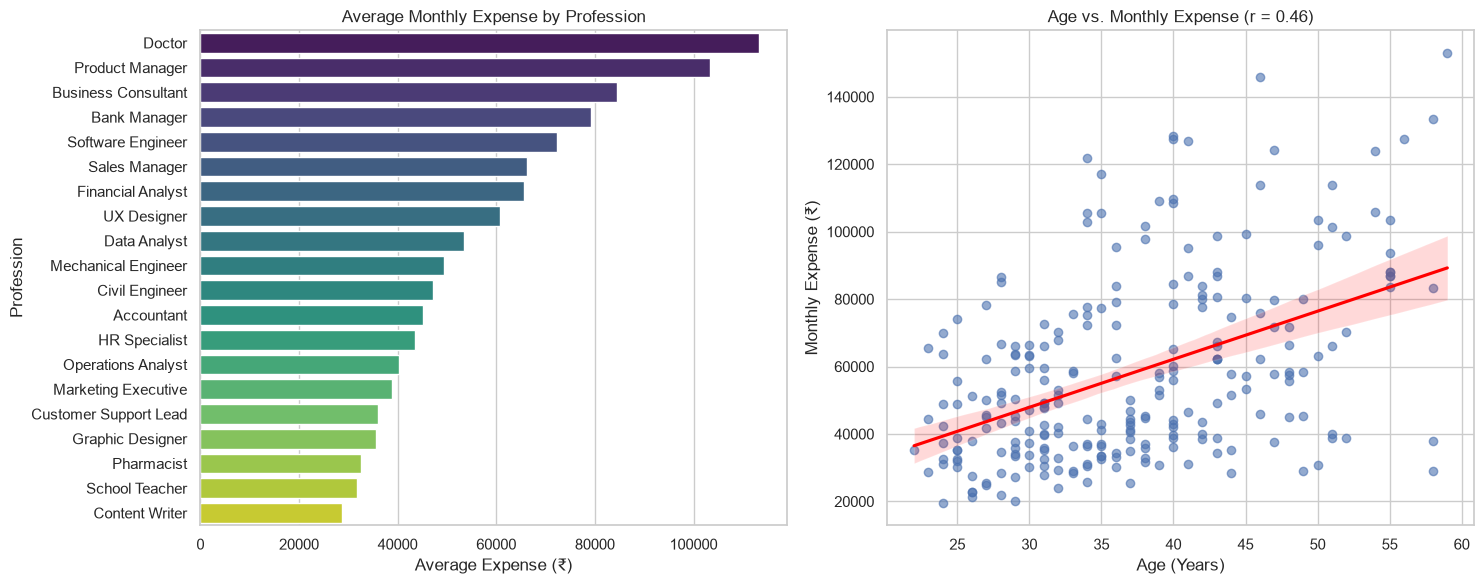

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the dataset
df = pd.read_csv('monthly_expenses_250.csv')

# 2. Clean the 'Monthly Expense' column and convert to numeric
df['Monthly Expense'] = pd.to_numeric(
    df['Monthly Expense'].astype(str).str.replace(r'[^\d.]', '', regex=True),
    errors='coerce'
)

# 3. General Dataset Overview
print("--- DATASET INFO ---")
print(f"Total Records: {len(df)}")
print(f"Missing Values:\n{df.isnull().sum()}\n")

print("--- SUMMARY STATISTICS ---")
print(df[['Age', 'Monthly Expense']].describe().round(2), "\n")

# 4. Correlation between Age and Monthly Expense
correlation = df['Age'].corr(df['Monthly Expense'])
print(f"Correlation (Age vs. Monthly Expense): {correlation:.2f}\n")

# 5. Spending & Headcount by Profession
job_summary = df.groupby('Job').agg(
    Headcount=('Name', 'count'),
    Avg_Expense=('Monthly Expense', 'mean'),
    Median_Expense=('Monthly Expense', 'median')
).round(2).sort_values(by='Avg_Expense', ascending=False)

print("--- TOP 5 HIGHEST SPENDING PROFESSIONS ---")
print(job_summary.head(5), "\n")

print("--- TOP 5 LOWEST SPENDING PROFESSIONS ---")
print(job_summary.tail(5), "\n")

# 6. Visualizations
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Average Monthly Expense by Profession
sns.barplot(
    x=job_summary['Avg_Expense'],
    y=job_summary.index,
    ax=axes[0],
    palette='viridis'
)
axes[0].set_title('Average Monthly Expense by Profession')
axes[0].set_xlabel('Average Expense (₹)')
axes[0].set_ylabel('Profession')

# Plot 2: Age vs. Monthly Expense Scatter Plot with Trendline
sns.regplot(
    data=df,
    x='Age',
    y='Monthly Expense',
    ax=axes[1],
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)
axes[1].set_title(f'Age vs. Monthly Expense (r = {correlation:.2f})')
axes[1].set_xlabel('Age (Years)')
axes[1].set_ylabel('Monthly Expense (₹)')

plt.tight_layout()
plt.show()